# Projekt zaliczeniowy: Diagnostyka nowotworów piersi
**Cel projektu:** Zbudowanie modelu klasyfikacji binarnej, który na podstawie pomiarów komórek z biopsji rozpozna, czy zmiana jest **złośliwa - 0** czy **łagodna - 1**.

**Metryka**
* **Accuracy (dokładność) > 90%**.
* **Wysoki Recall (czułość) dla klasy 0 (złośliwej)** – w medycynie najważniejsze jest to, aby nie przeoczyć chorej pacjentki (unikamy błędów *False Negative*).


Wczytuję podstawowe biblioteki, których używaliśmy na kursie: pandas do tabel, seaborn i matplotlib do wykresów oraz scikit-learn do modeli.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

#dane
data = load_breast_cancer(as_frame=True)
df = data.frame

#pierwsze 5 wierszy
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Sprawdzam rozmiar tabeli, czy nie ma brakujących wartości (NaN) oraz jak wygląda podział na przypadki złośliwe (0) i łagodne (1).

In [2]:
print("Rozmiar tabeli (wiersze, kolumny):", df.shape)
print("Suma pustych wartości (NaN):", df.isnull().sum().sum())
print("\nLiczba przypadków (0 = złośliwy, 1 = łagodny):")
print(df['target'].value_counts())

Rozmiar tabeli (wiersze, kolumny): (569, 31)
Suma pustych wartości (NaN): 0

Liczba przypadków (0 = złośliwy, 1 = łagodny):
target
1    357
0    212
Name: count, dtype: int64


Dane są kompletne (0 braków). Zobaczmy na wykresie pudełkowym, jak różni się średni promień komórki (mean radius) u pacjentek ze zmianą złośliwą i łagodną.

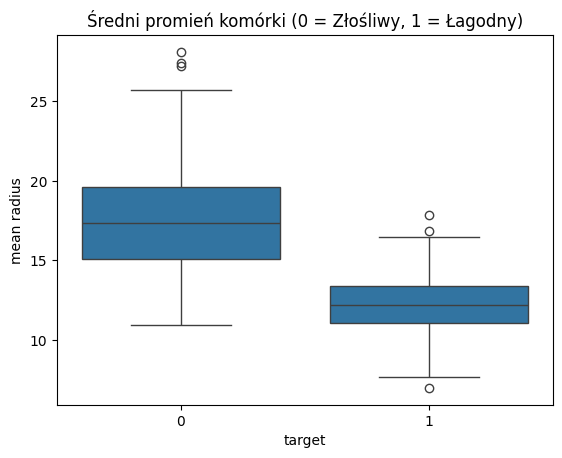

In [3]:
sns.boxplot(data=df, x='target', y='mean radius')
plt.title("Średni promień komórki (0 = Złośliwy, 1 = Łagodny)")
plt.show()

Sprawdzam jeszcze mapę korelacji dla pierwszych 10 cech, aby zobaczyć zależności między pomiarami.

In [4]:

df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


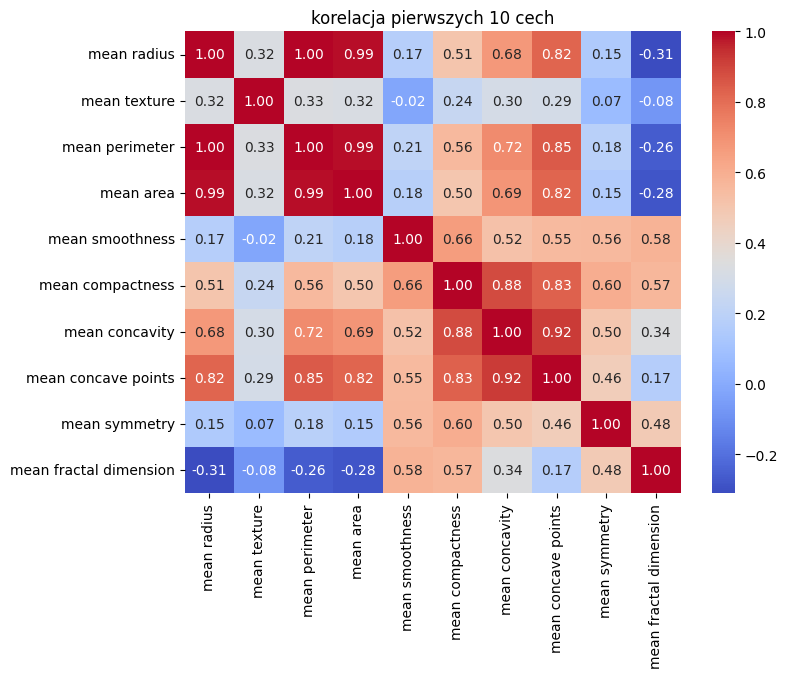

In [5]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.iloc[:, :10].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("korelacja pierwszych 10 cech")
plt.show()

**Wnioski z eksploaracji** Guzy złośliwe (0) mają wyraźnie większy promień niż łagodne (1). Cechy geometryczne (promień, obwód, pole powierzchni) są ze sobą silnie skorelowane.

## Przygotowanie danych
Oddzielam cechy (`X`) od diagnozy (`y`), dzielę dane na zbiór treningowy (80%) i testowy (20%), a następnie przeskalowuję wartości, ponieważ kolumny mają różne skale liczbowe.

In [6]:
#podział na cechy (X) i diagnozę (y)
X = df.drop('target', axis=1)
y = df['target']

#podział na zbiór treningowy (80%) i testowy (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#skalowanie danych
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Porównuję dwa modele: prostą **Regresję Logistyczną** (jako nasz model bazowy) oraz **Random Forest**. Wybiorę ten, który osiągnie wyższą dokładność na zbiorze testowym.

In [12]:
# 1. Regresja Logistyczna
model_log = LogisticRegression(random_state=42)
model_log.fit(X_train_scaled, y_train)

# 2. Random forest
model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train_scaled, y_train)

#porównanie wyników dokładności (Accuracy) na zbiorze testowym
print("Dokładność Regresji Logistycznej:", round(model_log.score(X_test_scaled, y_test), 4))
print("Dokładność Random forest:", round(model_rf.score(X_test_scaled, y_test), 4))

Dokładność Regresji Logistycznej: 0.9737
Dokładność Random forest: 0.9649


### Porównanie wymiarów guza dla zmian złośliwych i łagodnych
Sprawdźmy na prostym wykresie pudełkowym , czy średni promień komórki (mean radius) różni się u pacjentek zdrowych i chorych.

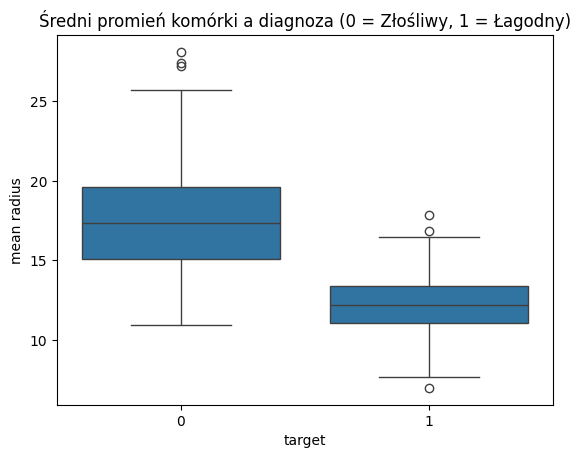

In [8]:
# rysujemy wykres pudełkowy dla średniego promienia (mean radius)
sns.boxplot(data=df, x='target', y='mean radius')
plt.title("Średni promień komórki a diagnoza (0 = Złośliwy, 1 = Łagodny)")
plt.show()


Regresja Logistyczna poradziła sobie najlepiej (**97.37% dokładności**), dlatego wybieram ją jako model końcowy. Sprawdzam szczegółowy raport metryk (w tym kluczowy Recall) oraz rysuję macierz pomyłek.

              precision    recall  f1-score   support

0 - Złośliwy       0.98      0.95      0.96        43
 1 - Łagodny       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



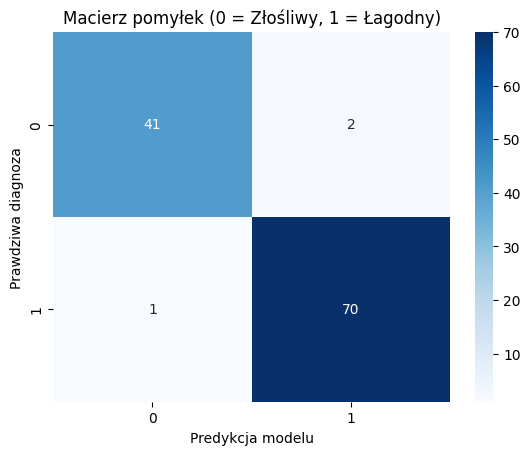

In [9]:
#predykcja naszego najlepszego modelu na zbiorze testowym
y_pred = model_log.predict(X_test_scaled)

#wyświetlenie raportu metryk
print(classification_report(y_test, y_pred, target_names=['0 - Złośliwy', '1 - Łagodny']))

#macierz pomyłek
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Macierz pomyłek (0 = Złośliwy, 1 = Łagodny)")
plt.xlabel("Predykcja modelu")
plt.ylabel("Prawdziwa diagnoza")
plt.show()

**Interpretacja wyników medycznych:**
* Na 114 pacjentek ze zbioru testowego model pomylił się tylko **3 razy**.
* **Recall dla klasy złośliwej (0) wynosi 95%** (wykryto 41 z 43 złośliwych przypadków), a **Precision aż 98%**.

## SHAP
W medycynie lekarz musi wiedzieć, dlaczego model podjął taką decyzję. Za pomocą biblioteki **SHAP** sprawdzam, które cechy komórki najbardziej wpływają na diagnozę.

Background dataset has 455 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=455 when initializing the masker.


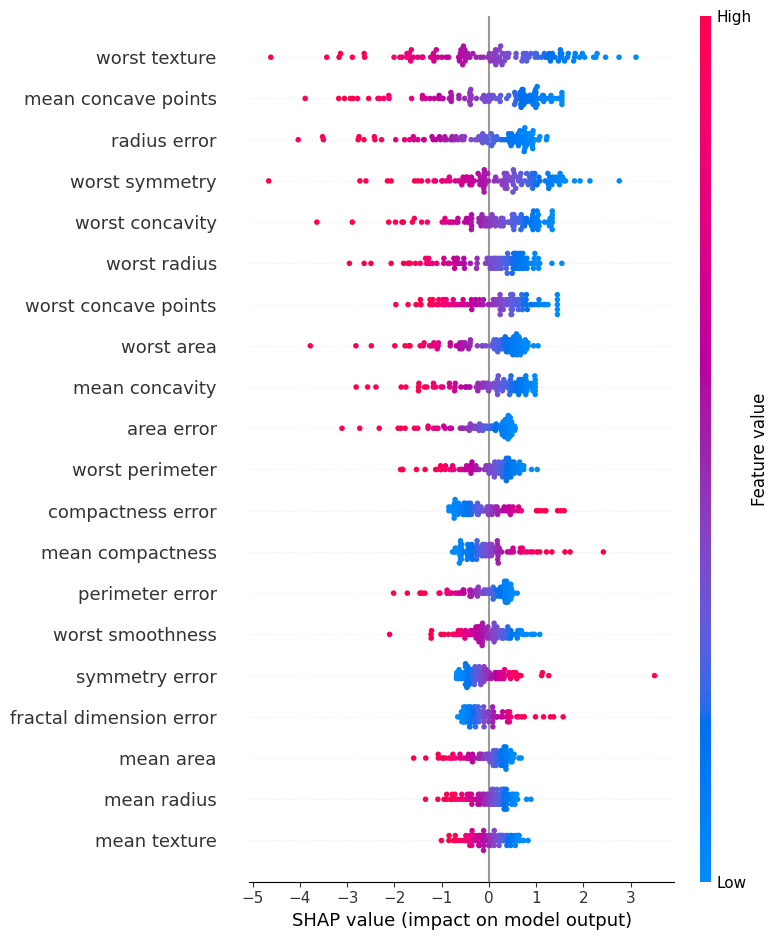

In [10]:
# Obliczenie wartości SHAP dla naszego modelu
explainer = shap.Explainer(model_log, X_train_scaled)
shap_values = explainer(X_test_scaled)

# Wykres pokazujący najważniejsze cechy
shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns)


### Podsumowanie projektu:
1.  Model Regresji Logistycznej osiągnął **97.4% Accuracy** oraz **95% Recall** dla zmian złośliwych, znacznie przekraczając wymagany próg 85%.
2. Po przeskalowaniu danych prosta Regresja Logistyczna okazała się skuteczniejsza od bardziej złożonego random forest (97.4% vs 96.5%).
3. Największy wpływ na diagnozę mają cechy opisujące najbardziej skrajne komórki w próbce: worst texture, worst radius (promień) oraz worst concave points (wklęsłości na obrysie jądra).

In [11]:
joblib.dump(model_log, 'model.joblib')
joblib.dump(scaler, 'scaler.joblib')
print("Model został zapisany")

Model został zapisany
